# Komparasi Kinerja SVM dan BiLSTM dalam Analisis Sentimen Ulasan Aplikasi Shopee di Google Play Store

Notebook ini mengimplementasikan rancangan penelitian pada draf proposal (Bab I–II) menjadi pipeline eksperimen yang dapat dijalankan ulang, sekaligus menghasilkan bahan **Hasil dan Pembahasan**.

**Desain eksperimen (diambil dari draf):**

| Aspek | Ketentuan pada draf | Implementasi di notebook |
|---|---|---|
| Data | Ulasan berbahasa Indonesia, Google Play; buang ulasan kosong & duplikat | `shopee_reviews_indonesia_raw.csv` (hasil `scraping.py`) |
| Label | Rating 4–5 positif, 3 netral, 1–2 negatif | Bagian 3 |
| Praproses | Hapus URL & simbol, tokenisasi, buang stopword, stemming | Bagian 4 (identik untuk kedua model) |
| Pembagian data | Berstrata, sama untuk kedua model | Bagian 6 (train 70 / val 10 / test 20) |
| Ketimpangan kelas | Pembobotan kelas pada kedua model | Bagian 7 |
| Model 1 | TF-IDF + SVM (one-against-all / one-against-one, beberapa kernel) | Bagian 8 |
| Model 2 | BiLSTM (lr, unit, dropout disetel) | Bagian 9 |
| Penyetelan | Prosedur setara (sama-sama pada data validasi, kriteria macro-F1) | Bagian 8–9 |
| Variasi inisialisasi | BiLSTM dilatih beberapa kali, dilaporkan rata-rata | 5 seed |
| Metrik | Accuracy, precision, recall, F1 (utama: macro-F1), waktu pelatihan & prediksi | Bagian 10–14 |
| Validasi label | Sampel anotasi manual | Bagian 5 |

**Rumusan masalah → bagian notebook:** RM1 (SVM) → 10 · RM2 (BiLSTM) → 10 · RM3 (model unggul) → 11 · RM4 (kelas pembeda) → 12 · RM5 (waktu komputasi) → 13.

## 1. Setup dan Konfigurasi

In [1]:
import os, re, time, json, random, warnings, platform
from pathlib import Path
from functools import lru_cache

os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import SVC, LinearSVC
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
                             f1_score, confusion_matrix, cohen_kappa_score)

import tensorflow as tf
from tensorflow.keras import layers, models, callbacks, optimizers

# ----- konfigurasi eksperimen -----
SEED = 42
LABELS = ["negatif", "netral", "positif"]          # indeks 0, 1, 2
TEST_SIZE, VAL_SIZE = 0.20, 0.10                   # train = 70%
FINAL_SEEDS = [11, 22, 33, 44, 55]                 # pelatihan ulang BiLSTM
EMB_DIM, BATCH_SIZE, MAX_EPOCHS, PATIENCE = 100, 64, 20, 3
N_BOOT = 2000                                      # replikasi bootstrap

DATA_CANDIDATES = ["dataset/shopee_reviews_indonesia_raw.csv", "shopee_reviews_indonesia_raw.csv"]
DATA_PATH = next((p for p in DATA_CANDIDATES if Path(p).exists()), None)
assert DATA_PATH, "Dataset tidak ditemukan. Letakkan CSV hasil scraping.py di folder dataset/."

OUT_DIR = Path("outputs"); FIG_DIR = OUT_DIR / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

def set_seed(s):
    random.seed(s); np.random.seed(s); tf.keras.utils.set_random_seed(s)
try:
    tf.config.experimental.enable_op_determinism()   # hasil BiLSTM dapat diulang pada mesin/jumlah thread yang sama
except Exception as e:
    print("op determinism tidak aktif:", e)
set_seed(SEED)

sns.set_theme(style="whitegrid", context="notebook")
C_SVM, C_LSTM = "#2B6CB0", "#DD6B20"               # biru = SVM, oranye = BiLSTM
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

print("Python", platform.python_version(), "| TensorFlow", tf.__version__, "| CPU threads:", os.cpu_count())
print("Dataset:", DATA_PATH)

I0000 00:00:1793605149.193201    5086 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


I0000 00:00:1793605150.502057    5086 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


Python 3.13.18 | TensorFlow 2.21.0 | CPU threads: 2
Dataset: dataset/shopee_reviews_indonesia_raw.csv


## 2. Data Mentah

Data diambil dengan `scraping.py` (pustaka `google-play-scraper`, aplikasi `com.shopee.id`, `lang="id"`, urutan terbaru). Skrip tersebut sudah membuang duplikat berdasarkan teks mentah dan baris kosong.

In [2]:
raw = pd.read_csv(DATA_PATH)
raw["at"] = pd.to_datetime(raw["at"])
print(f"Jumlah ulasan mentah : {len(raw):,}")
print(f"Rentang waktu ulasan : {raw['at'].min():%d %b %Y} – {raw['at'].max():%d %b %Y}")
print(f"Nilai kosong (text)  : {raw['text'].isna().sum()}")
display(raw[["text", "rating", "at"]].head(5))

Jumlah ulasan mentah : 11,726
Rentang waktu ulasan : 13 Oct 2026 – 01 Nov 2026
Nilai kosong (text)  : 0


,text,rating,at
0,sangat memuaskan,5,2026-11-01 12:30:30
1,pembayaran lancar sedetik pun tidak pernah tel...,1,2026-11-01 12:27:39
2,shopee tolong ya iklannya itu ngeselin bgtt ta...,2,2026-11-01 12:26:28
3,shopee mantap tapi kurangi toko pembohong,5,2026-11-01 12:24:54
4,mantap pokok nya😉😉,5,2026-11-01 12:22:54


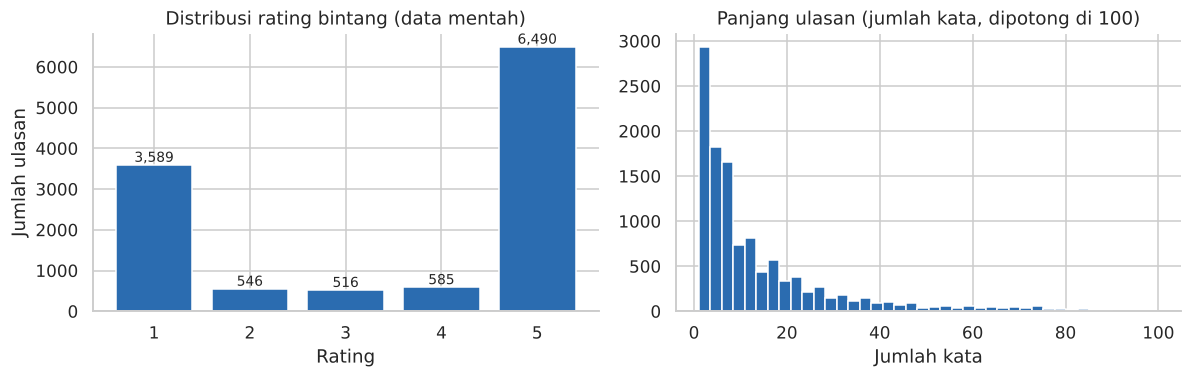

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
cnt = raw["rating"].value_counts().sort_index()
ax[0].bar(cnt.index.astype(str), cnt.values, color=C_SVM)
for x, v in zip(cnt.index.astype(str), cnt.values):
    ax[0].text(x, v, f"{v:,}", ha="center", va="bottom", fontsize=9)
ax[0].set_title("Distribusi rating bintang (data mentah)"); ax[0].set_xlabel("Rating"); ax[0].set_ylabel("Jumlah ulasan")
ax[1].hist(raw["text"].str.split().str.len().clip(upper=100), bins=40, color=C_SVM)
ax[1].set_title("Panjang ulasan (jumlah kata, dipotong di 100)"); ax[1].set_xlabel("Jumlah kata")
plt.tight_layout(); plt.savefig(FIG_DIR / "01_distribusi_data_mentah.png", dpi=150, bbox_inches="tight"); plt.show()

## 3. Pelabelan Sentimen dari Rating

Sesuai batasan penelitian 1.3 poin 2: rating 4–5 → **positif**, rating 3 → **netral**, rating 1–2 → **negatif**.

In [4]:
def rating_to_label(r):
    return 0 if r <= 2 else (1 if r == 3 else 2)

df = raw.dropna(subset=["text"]).copy()
df["text_raw"] = df["text"].astype(str)
df["y"] = df["rating"].map(rating_to_label)
df["label"] = df["y"].map(dict(enumerate(LABELS)))
print(df["label"].value_counts().reindex(LABELS).to_frame("jumlah").assign(persen=lambda d: (100*d.jumlah/d.jumlah.sum()).round(2)))

         jumlah  persen
label                  
negatif    4135   35.26
netral      516    4.40
positif    7075   60.34


## 4. Praproses Teks

Tahapan (sama untuk SVM dan BiLSTM agar perbandingan terkontrol):

1. *Case folding*, hapus URL, angka, tanda baca, dan emoji/simbol.
2. Pemadatan huruf berulang (`mantaaap` → `mantap`) dan **normalisasi kata tidak baku** (`gk`, `bgt`, `yg`, …) dengan kamus ringkas.
3. Pembuangan duplikat dan ulasan kosong setelah normalisasi, serta penyaringan ulasan yang jelas berbahasa Inggris.
4. *Stopword removal* (daftar Sastrawi) — **kata negasi dan penguat dipertahankan** (`tidak`, `bukan`, `belum`, `kurang`, `sangat`, …) karena membawa polaritas.
5. *Stemming* dengan Sastrawi.

In [ ]:
# Library Sastrawi untuk stemming dan stopword removal bahasa Indonesia
from Sastrawi.Stemmer.StemmerFactory import StemmerFactory
from Sastrawi.StopWordRemover.StopWordRemoverFactory import StopWordRemoverFactory

# --- kamus normalisasi kata tidak baku (disusun sendiri untuk penelitian ini) ---
SLANG = {
 "gk":"tidak","ga":"tidak","gak":"tidak","nggak":"tidak","ngga":"tidak","enggak":"tidak","engga":"tidak","tdk":"tidak","tak":"tidak","g":"tidak",
 "bgt":"sangat","bngt":"sangat","banget":"sangat","bgtt":"sangat","amat":"sangat",
 "udh":"sudah","udah":"sudah","sdh":"sudah","dah":"sudah","blm":"belum","belom":"belum",
 "yg":"yang","dgn":"dengan","dg":"dengan","utk":"untuk","buat":"untuk","jg":"juga","jga":"juga","sy":"saya","aq":"saya","gue":"saya","gw":"saya",
 "krn":"karena","karna":"karena","tp":"tapi","tpi":"tapi","sm":"sama","dr":"dari","trs":"terus","trus":"terus","bs":"bisa","bsa":"bisa",
 "gmn":"bagaimana","gimana":"bagaimana","knp":"kenapa","kenapa":"mengapa","lgi":"lagi","lg":"lagi","lgsg":"langsung","langsung":"langsung",
 "apk":"aplikasi","aplikasih":"aplikasi","app":"aplikasi","aplikasinya":"aplikasi","mantul":"mantap","mantab":"mantap","oke":"bagus","ok":"bagus","okey":"bagus",
 "bgus":"bagus","bagusss":"bagus","jlk":"jelek","jelek":"buruk","kcewa":"kecewa","kecewaa":"kecewa","parah":"buruk","muluk":"melulu",
 "brg":"barang","barangnya":"barang","org":"orang","pake":"pakai","pk":"pakai","skrg":"sekarang","sekrg":"sekarang","hrs":"harus","jd":"jadi","jdi":"jadi",
 "kyk":"seperti","kayak":"seperti","kaya":"seperti","mksh":"terima kasih","makasih":"terima kasih","thanks":"terima kasih","thx":"terima kasih",
 "lemot":"lambat","lola":"lambat","ngelag":"lag","error":"error","eror":"error","bnyk":"banyak","sgt":"sangat","sllu":"selalu","slalu":"selalu",
 "cuman":"hanya","cm":"hanya","doang":"saja","aja":"saja","aj":"saja","emg":"memang","emang":"memang","pdhl":"padahal","dlm":"dalam","sdkt":"sedikit",
 "ongkir":"ongkos kirim","cod":"cod","dpt":"dapat","dapet":"dapat","bkn":"bukan","bukannya":"bukan","ngeselin":"menyebalkan","nyebelin":"menyebalkan",
}
NEGATION_KEEP = {"tidak","bukan","belum","kurang","jangan","tanpa","sangat","sekali","cukup","lebih","paling","terlalu","hanya","masih","sudah","bisa","tak","mengapa","bagaimana"}
STOPWORDS = set(StopWordRemoverFactory().get_stop_words()) - NEGATION_KEEP
_stemmer = StemmerFactory().create_stemmer()

# Sastrawi lambat untuk kata di luar kamus (puluhan ms/kata). Hasil stemming per kata disimpan ke disk
# (cache) sehingga eksekusi ulang hampir instan. Kata > 14 huruf (umumnya ketikan acak) tidak di-stem.
CACHE_FILE = OUT_DIR / "stem_cache.json"
stem_cache = json.load(open(CACHE_FILE)) if CACHE_FILE.exists() else {}
def stem_word(w):
    if w not in stem_cache:
        stem_cache[w] = w if len(w) > 14 else _stemmer.stem(w)
    return stem_cache[w]

URL_RE = re.compile(r"(https?://\S+|www\.\S+)")
def norm_token(w):
    if w in SLANG: return SLANG[w]
    c = re.sub(r"(.)\1+", r"\1", w)               # 'bgtt' -> 'bgt', 'baguus' -> 'bagus'
    return SLANG.get(c, w)

def normalize(text):
    t = URL_RE.sub(" ", text.lower())
    t = re.sub(r"[^a-z\s]", " ", t)                # buang angka, tanda baca, emoji
    t = re.sub(r"(.)\1{2,}", r"\1", t)             # 3+ huruf berulang -> 1
    toks = [norm_token(w) for w in t.split()]
    return " ".join(w for w in " ".join(toks).split() if len(w) > 1)

def clean(text_norm):
    toks = [w for w in text_norm.split() if w not in STOPWORDS]
    return " ".join(stem_word(w) for w in toks)

demo = df["text_raw"].sample(5, random_state=3).tolist()
for d in demo:
    n = normalize(d); print("RAW  :", d[:110].replace("\n", " ")); print("NORM :", n[:110]); print("CLEAN:", clean(n)[:110]); print()

RAW  : Setiap kali belanja,pengiriman Pesanannya selalu lambat,dan Produk yang di jual dengan yang di foto Deskripsi 
NORM : setiap kali belanja pengiriman pesanannya selalu lambat dan produk yang di jual dengan yang di foto deskripsi 
CLEAN: kali belanja kirim pesan selalu lambat produk jual foto deskripsi banyak tidak sama

RAW  : shopee memang bagus tapi shopeelater sama pinjaman saya di bekukan
NORM : shopee memang bagus tapi shopeelater sama pinjaman saya di bekukan
CLEAN: shopee memang bagus shopeelater sama pinjam beku

RAW  : kenapa y shope nya q gax bisa cod semuanya
NORM : mengapa shope nya gax bisa cod semuanya
CLEAN: mengapa shope nya gax bisa cod semua

RAW  : bagus tapi jangan sering update aja, selebihnya saya suka
NORM : bagus tapi jangan sering update saja selebihnya saya suka
CLEAN: bagus jangan sering update lebih suka

RAW  : sukaa dehhhh belanja dishope
NORM : sukaa deh belanja dishope
CLEAN: sukaa deh belanja dishope



In [6]:
t0 = time.time()
n_awal = len(df)
df["text_norm"] = df["text_raw"].map(normalize)

# (a) ulasan kosong setelah normalisasi (mis. hanya emoji / angka)
df = df[df["text_norm"].str.len() > 0]; n_kosong = n_awal - len(df)

# (b) duplikat pada teks ternormalisasi (menghindari kebocoran data antara train dan test)
n_b = len(df); df = df.drop_duplicates(subset="text_norm", keep="first"); n_dup = n_b - len(df)

# (c) penyaringan ulasan berbahasa Inggris (heuristik kata fungsi)
EN = {"the","and","is","it","this","very","good","bad","not","but","with","for","you","my","to","of","in","so","can","great","nice","love","best","please","worst","fast","slow","service","product","order","delivery","thank","thanks","too","just","are","was","have","has"}
ID = {"yang","dan","tidak","ini","di","ke","dari","untuk","saya","aplikasi","bagus","sudah","belum","barang","kirim","sangat","banyak","juga","tapi","karena","dengan","bisa","mantap","buruk","lambat","terima","kasih","belanja","toko","pembayaran","ongkos","murah"}
def lang_flag(s):
    t = s.split(); e = sum(w in EN for w in t); i = sum(w in ID for w in t)
    return e >= 2 and e > i
mask_en = df["text_norm"].map(lang_flag)
n_en = int(mask_en.sum()); df = df[~mask_en]

df["text_clean"] = df["text_norm"].map(clean)
json.dump(stem_cache, open(CACHE_FILE, "w"))
n_b = len(df); df = df[df["text_clean"].str.len() > 0]; n_stop = n_b - len(df)   # (d) kosong setelah stopword
df = df.reset_index(drop=True)
df["n_tok"] = df["text_clean"].str.split().str.len()

print(f"Waktu praproses : {time.time()-t0:.1f} dtk")
print(pd.Series({"ulasan awal": n_awal, "kosong setelah normalisasi": -n_kosong, "duplikat (teks ternormalisasi)": -n_dup,
                 "terdeteksi berbahasa Inggris": -n_en, "kosong setelah stopword": -n_stop, "DATA AKHIR": len(df)}).to_frame("jumlah"))

Waktu praproses : 0.4 dtk
                                jumlah
ulasan awal                      11726
kosong setelah normalisasi        -115
duplikat (teks ternormalisasi)    -560
terdeteksi berbahasa Inggris      -106
kosong setelah stopword            -10
DATA AKHIR                       10935


,jumlah,persen
label,,
negatif,4058,37.11
netral,496,4.54
positif,6381,58.35


Rasio kelas mayoritas : minoritas = 12.9 : 1


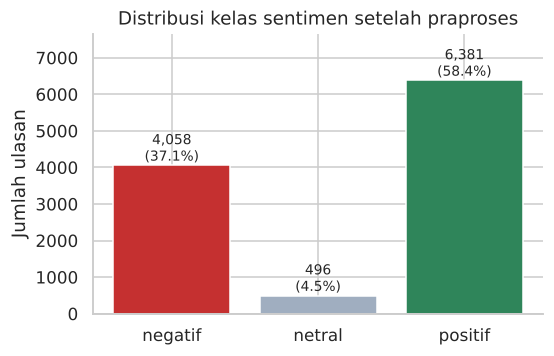

In [7]:
dist = df["label"].value_counts().reindex(LABELS)
tabel_dist = pd.DataFrame({"jumlah": dist, "persen": (100*dist/dist.sum()).round(2)})
display(tabel_dist)
print(f"Rasio kelas mayoritas : minoritas = {dist.max()/dist.min():.1f} : 1")
fig, ax = plt.subplots(figsize=(5.2, 3.4))
ax.bar(LABELS, dist.values, color=[ "#C53030", "#A0AEC0", "#2F855A"])
for i, v in enumerate(dist.values): ax.text(i, v, f"{v:,}\n({100*v/dist.sum():.1f}%)", ha="center", va="bottom", fontsize=9)
ax.set_ylim(0, dist.max()*1.2); ax.set_title("Distribusi kelas sentimen setelah praproses"); ax.set_ylabel("Jumlah ulasan")
plt.tight_layout(); plt.savefig(FIG_DIR / "02_distribusi_kelas.png", dpi=150, bbox_inches="tight"); plt.show()

## 5. Validasi Label pada Sampel Anotasi Manual

Draf mensyaratkan label dari rating **divalidasi pada sampel ulasan secara manual**. Sel di bawah mengekspor 150 ulasan acak berstrata (50 per kelas) ke `outputs/sampel_validasi_manual.csv`. Isi kolom `label_manual` dengan `negatif`/`netral`/`positif` (jangan melihat kolom rating saat menganotasi), simpan sebagai `outputs/sampel_validasi_manual_terisi.csv`, lalu jalankan ulang sel kedua untuk memperoleh akurasi kesesuaian dan Cohen's κ. Sel ini **tidak mengisi label sendiri**.

In [8]:
sample = (pd.concat([df[df["y"] == k].sample(50, random_state=SEED) for k in range(3)])
            .sample(frac=1, random_state=SEED)[["reviewId", "text_raw", "rating", "label"]]
            .rename(columns={"label": "label_rating"}))
sample["label_manual"] = ""
sample.to_csv(OUT_DIR / "sampel_validasi_manual.csv", index=False)
print("Sampel diekspor ->", OUT_DIR / "sampel_validasi_manual.csv", sample.shape)

Sampel diekspor -> outputs/sampel_validasi_manual.csv (150, 5)


In [9]:
filled = OUT_DIR / "sampel_validasi_manual_terisi.csv"
VALIDASI = None
if filled.exists():
    v = pd.read_csv(filled).dropna(subset=["label_manual"])
    v = v[v["label_manual"].isin(LABELS)]
    if len(v):
        acc = (v["label_manual"] == v["label_rating"]).mean()
        kappa = cohen_kappa_score(v["label_manual"], v["label_rating"])
        VALIDASI = {"n": len(v), "kesesuaian": acc, "kappa": kappa}
        print(f"n = {len(v)} | kesesuaian label rating vs manual = {acc:.1%} | Cohen's kappa = {kappa:.3f}")
        display(pd.crosstab(v["label_rating"], v["label_manual"]))
else:
    print("Belum ada file anotasi manual terisi -> validasi label dilewati (lihat petunjuk di atas).")

Belum ada file anotasi manual terisi -> validasi label dilewati (lihat petunjuk di atas).


## 6. Pembagian Data (Berstrata)

Satu pembagian dipakai oleh **kedua model**: 70% latih, 10% validasi (penyetelan hyperparameter & *early stopping*), 20% uji (hanya dipakai sekali di tahap akhir). Pembagian berstrata menjaga proporsi kelas netral yang kecil.

In [10]:
idx = np.arange(len(df))
idx_trval, idx_test = train_test_split(idx, test_size=TEST_SIZE, stratify=df["y"], random_state=SEED)
idx_train, idx_val = train_test_split(idx_trval, test_size=VAL_SIZE/(1-TEST_SIZE), stratify=df["y"].iloc[idx_trval], random_state=SEED)

X = df["text_clean"].values; y = df["y"].values
Xtr, ytr = X[idx_train], y[idx_train]; Xva, yva = X[idx_val], y[idx_val]; Xte, yte = X[idx_test], y[idx_test]
split_tbl = pd.DataFrame({n: np.bincount(v, minlength=3) for n, v in [("train", ytr), ("val", yva), ("test", yte)]}, index=LABELS)
split_tbl.loc["total"] = split_tbl.sum(); display(split_tbl)

,train,val,test
negatif,2840,406,812
netral,347,50,99
positif,4467,638,1276
total,7654,1094,2187


## 7. Penanganan Ketimpangan Kelas (Pembobotan Kelas)

Bobot kelas *balanced* dihitung dari data latih dan dipakai **sama** oleh SVM (`class_weight`) dan BiLSTM (`class_weight` Keras).

In [11]:
cw = compute_class_weight("balanced", classes=np.array([0, 1, 2]), y=ytr)
CLASS_W = {i: float(w) for i, w in enumerate(cw)}
print({LABELS[i]: round(w, 3) for i, w in CLASS_W.items()})

{'negatif': 0.898, 'netral': 7.353, 'positif': 0.571}


### Fungsi bantu evaluasi

In [12]:
def evaluate(y_true, y_pred):
    p, r, f, s = precision_recall_fscore_support(y_true, y_pred, labels=[0, 1, 2], zero_division=0)
    return {"accuracy": accuracy_score(y_true, y_pred),
            "macro_precision": p.mean(), "macro_recall": r.mean(), "macro_f1": f.mean(),
            "weighted_f1": f1_score(y_true, y_pred, average="weighted", zero_division=0),
            **{f"precision_{LABELS[i]}": p[i] for i in range(3)},
            **{f"recall_{LABELS[i]}": r[i] for i in range(3)},
            **{f"f1_{LABELS[i]}": f[i] for i in range(3)}}

def macro_f1_fast(y_true, y_pred, k=3):
    cm = np.bincount(y_true * k + y_pred, minlength=k * k).reshape(k, k)
    tp = np.diag(cm).astype(float); fp = cm.sum(0) - tp; fn = cm.sum(1) - tp
    d = 2 * tp + fp + fn
    f1 = np.divide(2 * tp, d, out=np.zeros(k), where=d > 0)
    return f1.mean(), f1

## 8. Model 1 — TF-IDF + SVM

Representasi: TF-IDF (`sublinear_tf`, `min_df=2`), kosakata hanya dari data latih. Penyetelan pada **data validasi** dengan kriteria macro-F1, mencakup:

* rentang n-gram: unigram vs. unigram+bigram,
* strategi multikelas: **one-against-all** (`LinearSVC`) dan **one-against-one** (`SVC`),
* kernel `SVC`: linear, RBF, sigmoid,
* parameter regularisasi `C`.

In [13]:
t0 = time.time()
svm_rows, vec_cache = [], {}
for ngram in [(1, 1), (1, 2)]:
    vec = TfidfVectorizer(ngram_range=ngram, min_df=2, sublinear_tf=True)
    Atr = vec.fit_transform(Xtr); Ava = vec.transform(Xva); vec_cache[ngram] = vec
    configs = [("OvA", "linear", C) for C in [0.1, 0.3, 1, 3, 10]] + \
              [("OvO", k, C) for k in ["linear", "rbf", "sigmoid"] for C in [0.1, 1, 10]]
    for strat, kernel, C in configs:
        clf = (LinearSVC(C=C, class_weight=CLASS_W, random_state=SEED) if strat == "OvA"
               else SVC(kernel=kernel, C=C, class_weight=CLASS_W, random_state=SEED))
        clf.fit(Atr, ytr)
        svm_rows.append({"ngram": ngram, "strategi": strat, "kernel": kernel, "C": C,
                         "val_macro_f1": f1_score(yva, clf.predict(Ava), average="macro")})
svm_grid = pd.DataFrame(svm_rows).sort_values("val_macro_f1", ascending=False).reset_index(drop=True)
print(f"Penyetelan SVM selesai: {len(svm_grid)} konfigurasi, {time.time()-t0:.0f} dtk")
display(svm_grid.head(10).style.format({"val_macro_f1": "{:.4f}"}))
best_svm = svm_grid.iloc[0].to_dict(); print("\nKonfigurasi SVM terpilih:", best_svm)
svm_grid.to_csv(OUT_DIR / "tuning_svm.csv", index=False)

Penyetelan SVM selesai: 28 konfigurasi, 124 dtk


,ngram,strategi,kernel,C,val_macro_f1
0,"(1, 1)",OvO,linear,0.100000,0.6088
1,"(1, 2)",OvO,linear,0.100000,0.6055
2,"(1, 2)",OvA,linear,0.300000,0.6046
3,"(1, 1)",OvA,linear,1.000000,0.6033
4,"(1, 1)",OvO,rbf,1.000000,0.5977
5,"(1, 2)",OvA,linear,0.100000,0.5964
6,"(1, 2)",OvA,linear,1.000000,0.5950
7,"(1, 2)",OvO,rbf,1.000000,0.5946
8,"(1, 2)",OvO,linear,1.000000,0.5943
9,"(1, 1)",OvA,linear,3.000000,0.5938



Konfigurasi SVM terpilih: {'ngram': (1, 1), 'strategi': 'OvO', 'kernel': 'linear', 'C': 0.1, 'val_macro_f1': 0.6087814239890411}


In [14]:
# Pelatihan akhir SVM pada data latih, lalu evaluasi sekali pada data uji.
def build_svm(cfg):
    vec = TfidfVectorizer(ngram_range=tuple(cfg["ngram"]), min_df=2, sublinear_tf=True)
    clf = (LinearSVC(C=cfg["C"], class_weight=CLASS_W, random_state=SEED) if cfg["strategi"] == "OvA"
           else SVC(kernel=cfg["kernel"], C=cfg["C"], class_weight=CLASS_W, random_state=SEED))
    return vec, clf

t0 = time.perf_counter(); vec, svm = build_svm(best_svm)
A_tr = vec.fit_transform(Xtr); svm.fit(A_tr, ytr)
svm_train_time = time.perf_counter() - t0

pred_times = []
for _ in range(5):                              # prediksi diulang 5x; ambil median
    t0 = time.perf_counter(); pred_svm = svm.predict(vec.transform(Xte)); pred_times.append(time.perf_counter() - t0)
svm_pred_time = float(np.median(pred_times))
m_svm = evaluate(yte, pred_svm)
print(f"SVM  | accuracy={m_svm['accuracy']:.4f}  macro-F1={m_svm['macro_f1']:.4f} | latih {svm_train_time:.2f} dtk, prediksi {svm_pred_time:.3f} dtk | fitur: {A_tr.shape[1]:,}")

SVM  | accuracy=0.7462  macro-F1=0.5869 | latih 5.98 dtk, prediksi 0.982 dtk | fitur: 2,926


**Varian pendamping — SVM one-against-all (`LinearSVC`).** Model terpilih di atas (kernel `SVC`) memakai vektor pendukung sehingga prediksinya relatif lambat. Agar perbandingan waktu komputasi (RM5) adil dan tidak bergantung pada satu pilihan implementasi SVM, konfigurasi OvA terbaik pada data validasi dievaluasi juga sebagai pembanding.

In [15]:
best_ova = svm_grid[svm_grid["strategi"] == "OvA"].iloc[0].to_dict()
t0 = time.perf_counter(); vec_o, ova = build_svm(best_ova)
A_o = vec_o.fit_transform(Xtr); ova.fit(A_o, ytr); ova_train_time = time.perf_counter() - t0
pt = []
for _ in range(5):
    t0 = time.perf_counter(); pred_ova = ova.predict(vec_o.transform(Xte)); pt.append(time.perf_counter() - t0)
ova_pred_time = float(np.median(pt)); m_ova = evaluate(yte, pred_ova)
print("Konfigurasi OvA terbaik:", {k: best_ova[k] for k in ["ngram", "C"]})
print(f"SVM OvA | accuracy={m_ova['accuracy']:.4f}  macro-F1={m_ova['macro_f1']:.4f} | latih {ova_train_time:.2f} dtk, prediksi {ova_pred_time:.3f} dtk | fitur: {A_o.shape[1]:,}")

Konfigurasi OvA terbaik: {'ngram': (1, 2), 'C': 0.3}
SVM OvA | accuracy=0.8409  macro-F1=0.6173 | latih 0.25 dtk, prediksi 0.042 dtk | fitur: 11,588


## 9. Model 2 — BiLSTM

Representasi: indeks kata (kosakata dari data latih), *embedding* 100 dimensi dilatih dari awal (seperti Ramadhan & Kusnawi, 2026), panjang urutan = persentil ke-95 panjang data latih. Arsitektur: `Embedding → Bidirectional(LSTM) → Dropout → Dense softmax`, optimizer Adam, *early stopping* pada `val_loss` (sabar 3 epoch, bobot terbaik dipulihkan).

Penyetelan pada **data validasi yang sama** dengan kriteria macro-F1; grid mengacu pada rentang yang dilaporkan literatur (Simanihuruk & Suparwito, 2025): learning rate {0,01; 0,001}, unit {64; 128}, dropout {0,2; 0,5}.

In [16]:
tok_len = pd.Series([len(s.split()) for s in Xtr])
MAX_LEN = int(np.ceil(tok_len.quantile(0.95)))
vocab = {}
for s in Xtr:
    for w in s.split(): vocab[w] = vocab.get(w, 0) + 1
word_index = {w: i + 2 for i, (w, _) in enumerate(sorted(vocab.items(), key=lambda kv: -kv[1]))}   # 0=pad, 1=OOV
VOCAB_SIZE = len(word_index) + 2
print(f"MAX_LEN = {MAX_LEN} | ukuran kosakata = {VOCAB_SIZE:,}")

def to_seq(texts):
    out = np.zeros((len(texts), MAX_LEN), dtype="int32")
    for i, s in enumerate(texts):
        ids = [word_index.get(w, 1) for w in s.split()][:MAX_LEN]
        out[i, :len(ids)] = ids
    return out

Str, Sva, Ste = to_seq(Xtr), to_seq(Xva), to_seq(Xte)

def build_bilstm(units, dropout, lr):
    m = models.Sequential([
        layers.Input(shape=(MAX_LEN,)),
        layers.Embedding(VOCAB_SIZE, EMB_DIM, mask_zero=True),
        layers.Bidirectional(layers.LSTM(units, dropout=dropout)),
        layers.Dropout(dropout),
        layers.Dense(3, activation="softmax")])
    m.compile(optimizer=optimizers.Adam(learning_rate=lr), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return m

def fit_bilstm(units, dropout, lr, seed):
    set_seed(seed)
    m = build_bilstm(units, dropout, lr)
    es = callbacks.EarlyStopping(monitor="val_loss", patience=PATIENCE, restore_best_weights=True)
    h = m.fit(Str, ytr, validation_data=(Sva, yva), epochs=MAX_EPOCHS, batch_size=BATCH_SIZE,
              class_weight=CLASS_W, callbacks=[es], verbose=0)
    return m, h

MAX_LEN = 39 | ukuran kosakata = 7,075


In [17]:
t0 = time.time(); lstm_rows = []
for lr in [0.01, 0.001]:
    for units in [64, 128]:
        for dr in [0.2, 0.5]:
            m, h = fit_bilstm(units, dr, lr, SEED)
            pv = m.predict(Sva, verbose=0).argmax(1)
            lstm_rows.append({"lr": lr, "units": units, "dropout": dr, "epoch_terbaik": int(np.argmin(h.history["val_loss"])) + 1,
                              "val_macro_f1": f1_score(yva, pv, average="macro")})
            print(lstm_rows[-1])
lstm_grid = pd.DataFrame(lstm_rows).sort_values("val_macro_f1", ascending=False).reset_index(drop=True)
print(f"\nPenyetelan BiLSTM selesai: {len(lstm_grid)} konfigurasi, {time.time()-t0:.0f} dtk")
display(lstm_grid.style.format({"val_macro_f1": "{:.4f}"}))
best_lstm = lstm_grid.iloc[0].to_dict(); print("Konfigurasi BiLSTM terpilih:", best_lstm)
lstm_grid.to_csv(OUT_DIR / "tuning_bilstm.csv", index=False)

E0000 00:00:1793605288.335263    5086 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_16}}


E0000 00:00:1793605292.311615    5086 util.cc:131] oneDNN supports DT_BOOL only on platforms with AVX-512. Falling back to the default Eigen-based implementation if present.


E0000 00:00:1793605297.993341    5086 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}


E0000 00:00:1793605328.741303    5086 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}


{'lr': 0.01, 'units': 64, 'dropout': 0.2, 'epoch_terbaik': 1, 'val_macro_f1': 0.6128127461201694}


E0000 00:00:1793605338.970720    5086 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}


... (18 outputs left out)

E0000 00:00:1793605670.572684    5086 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}


{'lr': 0.001, 'units': 128, 'dropout': 0.5, 'epoch_terbaik': 3, 'val_macro_f1': 0.5971479285997084}

Penyetelan BiLSTM selesai: 8 konfigurasi, 384 dtk


,lr,units,dropout,epoch_terbaik,val_macro_f1
0,0.001000,64,0.500000,3,0.6238
1,0.001000,128,0.200000,2,0.6199
2,0.001000,64,0.200000,2,0.6196
3,0.010000,64,0.200000,1,0.6128
4,0.010000,64,0.500000,1,0.6044
5,0.001000,128,0.500000,3,0.5971
6,0.010000,128,0.200000,1,0.5966
7,0.010000,128,0.500000,1,0.5865


Konfigurasi BiLSTM terpilih: {'lr': 0.001, 'units': 64.0, 'dropout': 0.5, 'epoch_terbaik': 3.0, 'val_macro_f1': 0.6237817520901424}


In [18]:
# Pelatihan akhir BiLSTM: 5 inisialisasi acak berbeda (data & hyperparameter sama).
runs = []
for sd in FINAL_SEEDS:
    t0 = time.perf_counter()
    m, h = fit_bilstm(int(best_lstm["units"]), best_lstm["dropout"], best_lstm["lr"], sd)
    train_t = time.perf_counter() - t0

    pt = []
    for _ in range(3):
        t0 = time.perf_counter(); proba = m.predict(to_seq(Xte), verbose=0, batch_size=256); pt.append(time.perf_counter() - t0)
    pred = proba.argmax(1)
    r = {"seed": sd, "epochs_ditempuh": len(h.history["loss"]), "epoch_terbaik": int(np.argmin(h.history["val_loss"])) + 1,
         "train_time": train_t, "pred_time": float(np.median(pt)), "pred": pred, "history": h.history, **evaluate(yte, pred)}
    runs.append(r)
    print(f"seed {sd:>2} | epoch {r['epochs_ditempuh']:>2} (terbaik {r['epoch_terbaik']:>2}) | acc={r['accuracy']:.4f} macro-F1={r['macro_f1']:.4f} | latih {train_t:.1f} dtk, prediksi {r['pred_time']:.2f} dtk")
n_params = m.count_params(); print("Jumlah parameter BiLSTM:", f"{n_params:,}")

E0000 00:00:1793605681.757407    5086 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}


E0000 00:00:1793605711.234761    5086 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}


seed 11 | epoch  5 (terbaik  2) | acc=0.7997 macro-F1=0.6192 | latih 39.2 dtk, prediksi 0.37 dtk


E0000 00:00:1793605723.199724    5086 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}


E0000 00:00:1793605753.541879    5086 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}


seed 22 | epoch  6 (terbaik  3) | acc=0.7938 macro-F1=0.6206 | latih 40.5 dtk, prediksi 0.37 dtk


... (5 outputs left out)

seed 44 | epoch  6 (terbaik  3) | acc=0.7316 macro-F1=0.5867 | latih 40.3 dtk, prediksi 0.37 dtk


E0000 00:00:1793605860.795628    5086 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}


E0000 00:00:1793605877.668472    5086 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}


seed 55 | epoch  4 (terbaik  1) | acc=0.7988 macro-F1=0.6275 | latih 25.7 dtk, prediksi 0.34 dtk
Jumlah parameter BiLSTM: 792,367


## 10. Hasil RM1 & RM2 — Kinerja SVM dan BiLSTM pada Data Uji

In [19]:
metric_cols = ["accuracy", "macro_precision", "macro_recall", "macro_f1", "weighted_f1"]
lstm_df = pd.DataFrame([{k: r[k] for k in ["seed"] + metric_cols} for r in runs]).set_index("seed")
display(Markdown("**BiLSTM per seed**")); display(lstm_df.style.format("{:.4f}"))

summary = pd.DataFrame({
    "SVM (TF-IDF)": [m_svm[c] for c in metric_cols],
    "BiLSTM (rata-rata)": lstm_df.mean().values,
    "BiLSTM (std)": lstm_df.std(ddof=1).values}, index=metric_cols)
display(Markdown("**Ringkasan keseluruhan (data uji)**")); display(summary.style.format("{:.4f}"))
summary.to_csv(OUT_DIR / "hasil_keseluruhan.csv")

pc_rows = []
for i, lab in enumerate(LABELS):
    for met in ["precision", "recall", "f1"]:
        v = [r[f"{met}_{lab}"] for r in runs]
        pc_rows.append({"kelas": lab, "metrik": met, "SVM": m_svm[f"{met}_{lab}"], "SVM_OvA": m_ova[f"{met}_{lab}"], "BiLSTM_mean": np.mean(v), "BiLSTM_std": np.std(v, ddof=1)})
per_class = pd.DataFrame(pc_rows)
display(Markdown("**Metrik per kelas**"))
display(per_class.pivot(index="kelas", columns="metrik", values=["SVM", "SVM_OvA", "BiLSTM_mean", "BiLSTM_std"]).loc[LABELS].style.format("{:.4f}"))
per_class.to_csv(OUT_DIR / "hasil_per_kelas.csv", index=False)

**BiLSTM per seed**

,accuracy,macro_precision,macro_recall,macro_f1,weighted_f1
seed,,,,,
11,0.7997,0.6239,0.6410,0.6192,0.8208
22,0.7938,0.6206,0.6484,0.6206,0.8145
33,0.7449,0.6007,0.6132,0.5838,0.7841
44,0.7316,0.6169,0.6425,0.5867,0.7787
55,0.7988,0.6278,0.6590,0.6275,0.8211


**Ringkasan keseluruhan (data uji)**

,SVM (TF-IDF),BiLSTM (rata-rata),BiLSTM (std)
accuracy,0.7462,0.7738,0.0328
macro_precision,0.6113,0.6180,0.0105
macro_recall,0.6264,0.6408,0.0170
macro_f1,0.5869,0.6076,0.0206
weighted_f1,0.7863,0.8038,0.0207


**Metrik per kelas**

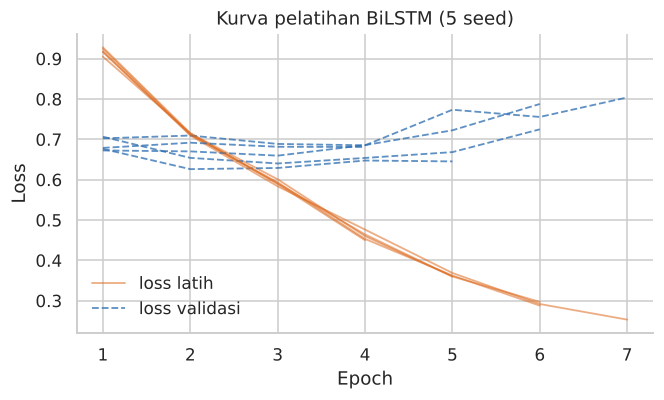

In [20]:
# Kurva pelatihan BiLSTM (indikator overfitting: val_loss naik setelah epoch tertentu)
fig, ax = plt.subplots(figsize=(6.2, 3.8))
for j, r in enumerate(runs):
    ax.plot(range(1, len(r["history"]["loss"]) + 1), r["history"]["loss"], color=C_LSTM, alpha=.55, lw=1.2, label="loss latih" if j == 0 else None)
    ax.plot(range(1, len(r["history"]["val_loss"]) + 1), r["history"]["val_loss"], color=C_SVM, alpha=.75, lw=1.2, ls="--", label="loss validasi" if j == 0 else None)
ax.set_xlabel("Epoch"); ax.set_ylabel("Loss"); ax.set_title("Kurva pelatihan BiLSTM (5 seed)"); ax.legend(frameon=False)
plt.tight_layout(); plt.savefig(FIG_DIR / "03_kurva_pelatihan_bilstm.png", dpi=150, bbox_inches="tight"); plt.show()

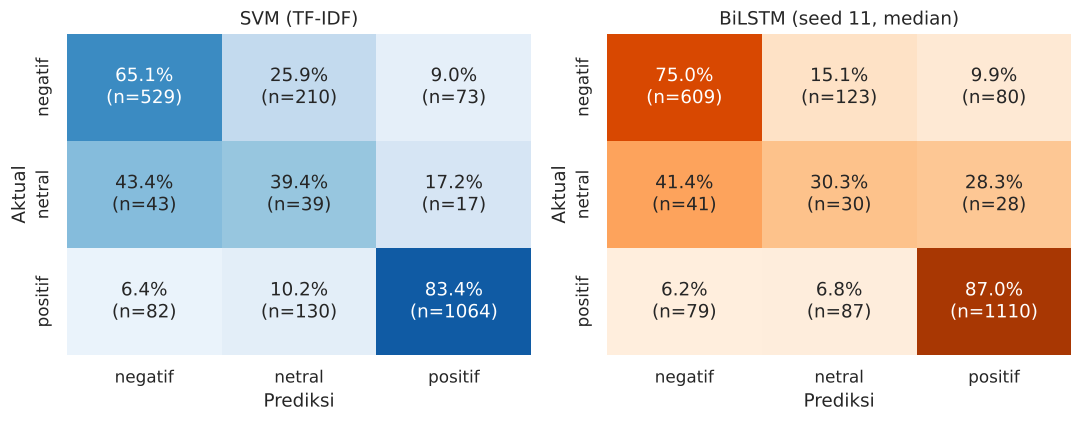

In [21]:
# Confusion matrix (dinormalisasi per baris = recall). BiLSTM: prediksi seed dengan macro-F1 median.
med = sorted(runs, key=lambda r: r["macro_f1"])[len(runs) // 2]
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, (name, pred, cmap) in zip(axes, [("SVM (TF-IDF)", pred_svm, "Blues"), (f"BiLSTM (seed {med['seed']}, median)", med["pred"], "Oranges")]):
    cm = confusion_matrix(yte, pred, labels=[0, 1, 2]); cmn = cm / cm.sum(1, keepdims=True)
    sns.heatmap(cmn, annot=np.array([[f"{cmn[i,j]:.1%}\n(n={cm[i,j]})" for j in range(3)] for i in range(3)]), fmt="", cmap=cmap,
                xticklabels=LABELS, yticklabels=LABELS, cbar=False, vmin=0, vmax=1, ax=ax)
    ax.set_title(name); ax.set_xlabel("Prediksi"); ax.set_ylabel("Aktual")
plt.tight_layout(); plt.savefig(FIG_DIR / "04_confusion_matrix.png", dpi=150, bbox_inches="tight"); plt.show()

## 11. Hasil RM3 — Model yang Lebih Unggul (macro-F1)

Karena data uji hanya satu sampel, selisih macro-F1 diuji dengan **bootstrap berpasangan** (resampling data uji yang sama untuk kedua model; BiLSTM = rata-rata macro-F1 lima seed pada resampel yang sama). Model dinyatakan unggul secara meyakinkan hanya jika selang kepercayaan 95% selisihnya tidak memuat nol.

,macro-F1,CI95 bawah,CI95 atas
SVM terpilih (SVC OvO),0.5869,0.5663,0.6074
SVM pendamping (LinearSVC OvA),0.6173,0.5903,0.6464
BiLSTM (rata-rata 5 seed),0.6076,0.5905,0.6252


Selisih macro-F1 (SVM − BiLSTM) = -0.0207  | CI95 bootstrap [-0.0369, -0.0045]  -> berbeda nyata (model nominal terbaik: BiLSTM)
Seed BiLSTM terbaik: macro-F1 = 0.6275; terburuk: 0.5838 | SVM = 0.5869
Seed BiLSTM yang macro-F1-nya melampaui SVM: 3 dari 5
Uji-t satu-sampel (macro-F1 5 seed BiLSTM vs SVM): t = 2.24, p = 0.089  (catatan: hanya n = 5 seed)
[Sensitivitas] SVM OvA (LinearSVC) − BiLSTM = +0.0098 | CI95 bootstrap [-0.0156, +0.0377] -> tidak berbeda nyata
[Sensitivitas] macro-F1 validasi kedua konfigurasi SVM: terpilih 0.6088 vs OvA 0.6046 (selisih 0.0042) -> pemilihan pada satu data validasi tidak dapat membedakannya secara tegas


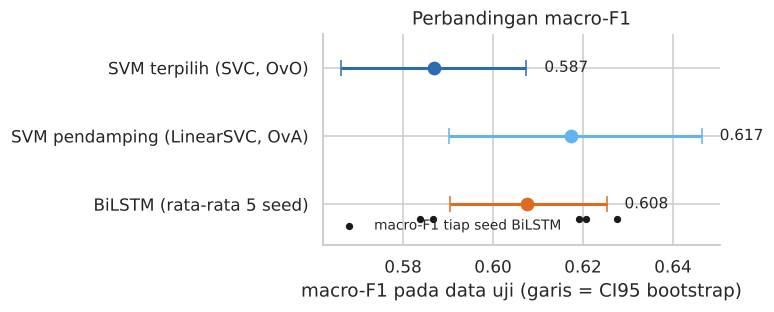

In [22]:
rng = np.random.default_rng(SEED); n = len(yte)
bs_svm, bs_lstm, bs_cls_s, bs_cls_l, bs_ova = [], [], [], [], []
for _ in range(N_BOOT):
    ix = rng.integers(0, n, n); yt = yte[ix]
    ms, fs = macro_f1_fast(yt, pred_svm[ix])
    res = [macro_f1_fast(yt, r["pred"][ix]) for r in runs]
    bs_svm.append(ms); bs_cls_s.append(fs); bs_ova.append(macro_f1_fast(yt, pred_ova[ix])[0])
    bs_lstm.append(np.mean([a for a, _ in res])); bs_cls_l.append(np.mean([b for _, b in res], axis=0))
bs_svm, bs_lstm, bs_ova = np.array(bs_svm), np.array(bs_lstm), np.array(bs_ova); bs_cls_s, bs_cls_l = np.array(bs_cls_s), np.array(bs_cls_l)
diff = bs_svm - bs_lstm; lo, hi = np.percentile(diff, [2.5, 97.5])

ci = lambda a: tuple(np.percentile(a, [2.5, 97.5]))
rm3 = pd.DataFrame({"macro-F1": [m_svm["macro_f1"], m_ova["macro_f1"], lstm_df["macro_f1"].mean()],
                    "CI95 bawah": [ci(bs_svm)[0], ci(bs_ova)[0], ci(bs_lstm)[0]], "CI95 atas": [ci(bs_svm)[1], ci(bs_ova)[1], ci(bs_lstm)[1]]},
                   index=["SVM terpilih (SVC OvO)", "SVM pendamping (LinearSVC OvA)", "BiLSTM (rata-rata 5 seed)"])
display(rm3.style.format("{:.4f}"))
delta = m_svm["macro_f1"] - lstm_df["macro_f1"].mean()
signif = not (lo <= 0 <= hi)
unggul = "SVM" if delta > 0 else "BiLSTM"
print(f"Selisih macro-F1 (SVM − BiLSTM) = {delta:+.4f}  | CI95 bootstrap [{lo:+.4f}, {hi:+.4f}]  -> {'berbeda nyata' if signif else 'tidak berbeda nyata'} (model nominal terbaik: {unggul})")
print(f"Seed BiLSTM terbaik: macro-F1 = {lstm_df['macro_f1'].max():.4f}; terburuk: {lstm_df['macro_f1'].min():.4f} | SVM = {m_svm['macro_f1']:.4f}")
n_above = int((lstm_df["macro_f1"] > m_svm["macro_f1"]).sum())
print(f"Seed BiLSTM yang macro-F1-nya melampaui SVM: {n_above} dari {len(runs)}")
from scipy import stats
tt = stats.ttest_1samp(lstm_df["macro_f1"], m_svm["macro_f1"])      # variasi antar-inisialisasi BiLSTM vs satu nilai SVM
print(f"Uji-t satu-sampel (macro-F1 5 seed BiLSTM vs SVM): t = {tt.statistic:.2f}, p = {tt.pvalue:.3f}  (catatan: hanya n = {len(runs)} seed)")
d_ova = bs_ova - bs_lstm; lo_o, hi_o = np.percentile(d_ova, [2.5, 97.5]); signif_ova = not (lo_o <= 0 <= hi_o)
delta_ova = m_ova["macro_f1"] - lstm_df["macro_f1"].mean()
print(f"[Sensitivitas] SVM OvA (LinearSVC) − BiLSTM = {delta_ova:+.4f} | CI95 bootstrap [{lo_o:+.4f}, {hi_o:+.4f}] -> {'berbeda nyata' if signif_ova else 'tidak berbeda nyata'}")
print(f"[Sensitivitas] macro-F1 validasi kedua konfigurasi SVM: terpilih {best_svm['val_macro_f1']:.4f} vs OvA {best_ova['val_macro_f1']:.4f} (selisih {best_svm['val_macro_f1']-best_ova['val_macro_f1']:.4f}) -> pemilihan pada satu data validasi tidak dapat membedakannya secara tegas")

fig, ax = plt.subplots(figsize=(7.2, 3.0))
rows_ = [("SVM terpilih (SVC, OvO)", m_svm["macro_f1"], ci(bs_svm), C_SVM),
         ("SVM pendamping (LinearSVC, OvA)", m_ova["macro_f1"], ci(bs_ova), "#63B3ED"),
         ("BiLSTM (rata-rata 5 seed)", lstm_df["macro_f1"].mean(), ci(bs_lstm), C_LSTM)]
for i, (nm, v, (l, h), c) in enumerate(rows_):
    ax.errorbar(v, i, xerr=[[v - l], [h - v]], fmt="o", color=c, capsize=5, ms=8, lw=2)
    ax.text(h + 0.004, i, f"{v:.3f}", va="center", fontsize=10)
ax.scatter(lstm_df["macro_f1"], [2.22] * len(runs), color="k", s=14, zorder=3, label="macro-F1 tiap seed BiLSTM")
ax.set_yticks(range(3), [r[0] for r in rows_]); ax.set_ylim(2.6, -0.5)
ax.set_xlabel("macro-F1 pada data uji (garis = CI95 bootstrap)"); ax.set_title("Perbandingan macro-F1")
ax.legend(frameon=False, loc="lower left", fontsize=9)
plt.tight_layout(); plt.savefig(FIG_DIR / "05_macro_f1.png", dpi=150, bbox_inches="tight"); plt.show()

## 12. Hasil RM4 — Kelas Sentimen yang Paling Membedakan Kedua Model

,F1 SVM,F1 SVM OvA (pendamping),F1 BiLSTM,selisih (SVM−BiLSTM),CI95 bawah,CI95 atas,berbeda nyata
kelas,,,,,,,
negatif,0.7217,0.8198,0.7729,-0.0512,-0.0720,-0.0322,True
netral,0.1632,0.1370,0.1776,-0.0144,-0.0511,+0.0216,False
positif,0.8757,0.8952,0.8721,+0.0036,-0.0063,+0.0126,False


Kelas dengan selisih F1 terbesar: negatif (-0.0512)


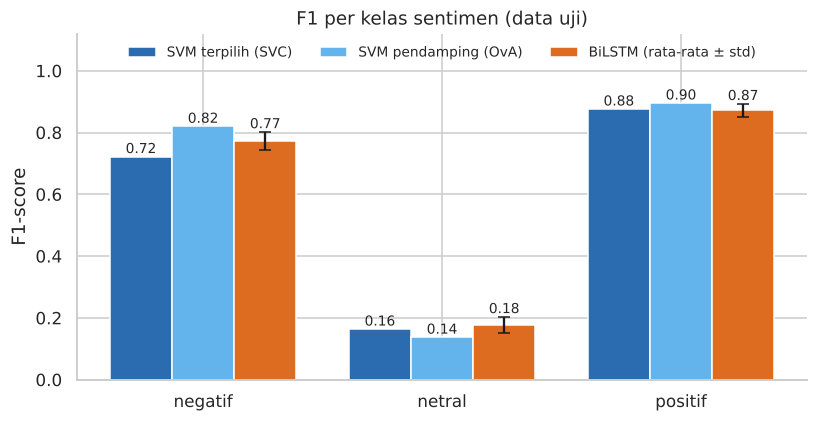

In [23]:
rows = []
for i, lab in enumerate(LABELS):
    d = bs_cls_s[:, i] - bs_cls_l[:, i]; l, h = np.percentile(d, [2.5, 97.5])
    rows.append({"kelas": lab, "F1 SVM": m_svm[f"f1_{lab}"], "F1 SVM OvA (pendamping)": m_ova[f"f1_{lab}"], "F1 BiLSTM": np.mean([r[f"f1_{lab}"] for r in runs]),
                 "selisih (SVM−BiLSTM)": m_svm[f"f1_{lab}"] - np.mean([r[f"f1_{lab}"] for r in runs]), "CI95 bawah": l, "CI95 atas": h,
                 "berbeda nyata": not (l <= 0 <= h)})
rm4 = pd.DataFrame(rows).set_index("kelas"); display(rm4.style.format({c: "{:+.4f}" if "selisih" in c or "CI" in c else "{:.4f}" for c in rm4.columns if c != "berbeda nyata"}))
kelas_beda = rm4["selisih (SVM−BiLSTM)"].abs().idxmax()
print(f"Kelas dengan selisih F1 terbesar: {kelas_beda} ({rm4.loc[kelas_beda, 'selisih (SVM−BiLSTM)']:+.4f})")
rm4.to_csv(OUT_DIR / "hasil_rm4_selisih_kelas.csv")

fig, ax = plt.subplots(figsize=(7.6, 4)); w = .26; x = np.arange(3)
err_l = np.array([np.std([r[f"f1_{l}"] for r in runs], ddof=1) for l in LABELS])
ax.bar(x - w, rm4["F1 SVM"], w, color=C_SVM, label="SVM terpilih (SVC)")
ax.bar(x, rm4["F1 SVM OvA (pendamping)"], w, color="#63B3ED", label="SVM pendamping (OvA)")
ax.bar(x + w, rm4["F1 BiLSTM"], w, color=C_LSTM, label="BiLSTM (rata-rata ± std)", yerr=err_l, capsize=4)
for xi, a, b, c, e in zip(x, rm4["F1 SVM"], rm4["F1 SVM OvA (pendamping)"], rm4["F1 BiLSTM"], err_l):
    ax.text(xi - w, a + .012, f"{a:.2f}", ha="center", fontsize=9); ax.text(xi, b + .012, f"{b:.2f}", ha="center", fontsize=9)
    ax.text(xi + w, c + e + .012, f"{c:.2f}", ha="center", fontsize=9)
ax.set_xticks(x, LABELS); ax.set_ylim(0, 1.12); ax.set_ylabel("F1-score"); ax.set_title("F1 per kelas sentimen (data uji)"); ax.legend(frameon=False, ncol=3, loc="upper center", fontsize=9)
plt.tight_layout(); plt.savefig(FIG_DIR / "06_f1_per_kelas.png", dpi=150, bbox_inches="tight"); plt.show()

In [24]:
# Analisis tambahan: kinerja menurut panjang ulasan (apakah BiLSTM diuntungkan pada teks yang lebih panjang?)
te = df.iloc[idx_test].reset_index(drop=True).copy()
te["bin"] = pd.cut(te["n_tok"], bins=[0, 2, 5, 10, 1000], labels=["1–2 kata", "3–5 kata", "6–10 kata", ">10 kata"])
rows = []
for b, g in te.groupby("bin", observed=True):
    ii = g.index.values
    rows.append({"panjang (setelah praproses)": b, "n": len(ii), "macro-F1 SVM": macro_f1_fast(yte[ii], pred_svm[ii])[0],
                 "macro-F1 BiLSTM": np.mean([macro_f1_fast(yte[ii], r["pred"][ii])[0] for r in runs]),
                 "acc SVM": (pred_svm[ii] == yte[ii]).mean(), "acc BiLSTM": np.mean([(r["pred"][ii] == yte[ii]).mean() for r in runs])})
len_tbl = pd.DataFrame(rows).set_index("panjang (setelah praproses)"); display(len_tbl.style.format("{:.4f}", subset=[c for c in len_tbl.columns if c != "n"]))
len_tbl.to_csv(OUT_DIR / "hasil_menurut_panjang.csv")

,n,macro-F1 SVM,macro-F1 BiLSTM,acc SVM,acc BiLSTM
panjang (setelah praproses),,,,,
1–2 kata,351,0.5697,0.4856,0.8291,0.7499
3–5 kata,660,0.5903,0.6374,0.8182,0.8464
6–10 kata,468,0.5697,0.6008,0.7543,0.8021
>10 kata,708,0.5410,0.5753,0.6328,0.6992


## 13. Hasil RM5 — Waktu Komputasi

,Waktu latih (dtk),Waktu prediksi data uji (dtk),Prediksi per 1.000 ulasan (dtk),macro-F1,Std waktu latih (dtk)
"SVM (SVC OvO, terpilih)",5.979,0.982,0.449,0.587,0.000
"SVM (LinearSVC OvA, pendamping)",0.253,0.042,0.019,0.617,0.000
BiLSTM (rata-rata 5 seed),39.639,0.357,0.163,0.608,9.523


Latih  : BiLSTM = 6.6x SVM terpilih, 157x SVM OvA.
Prediksi: BiLSTM = 0.36x SVM terpilih, 8.5x SVM OvA (perangkat sama, CPU 2 thread).
Epoch rata-rata BiLSTM: 5.6 | Parameter: 792,367


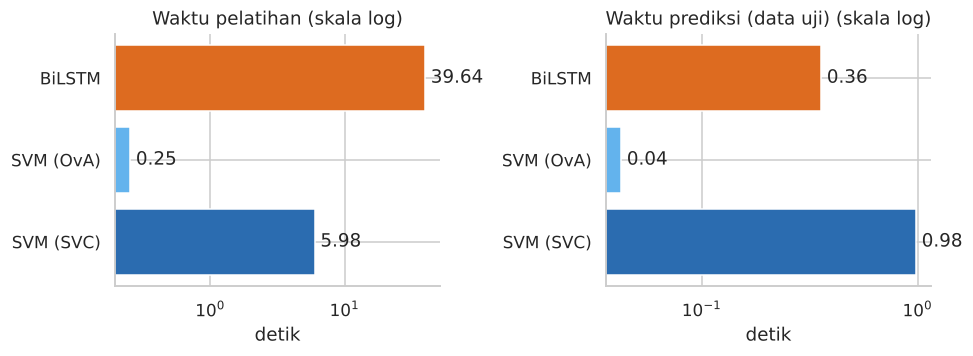

In [25]:
lstm_pred_mean = np.mean([r["pred_time"] for r in runs])
time_tbl = pd.DataFrame({
    "Waktu latih (dtk)": [svm_train_time, ova_train_time, np.mean([r["train_time"] for r in runs])],
    "Waktu prediksi data uji (dtk)": [svm_pred_time, ova_pred_time, lstm_pred_mean],
    "Prediksi per 1.000 ulasan (dtk)": [t / len(yte) * 1000 for t in (svm_pred_time, ova_pred_time, lstm_pred_mean)],
    "macro-F1": [m_svm["macro_f1"], m_ova["macro_f1"], lstm_df["macro_f1"].mean()]},
    index=["SVM (SVC OvO, terpilih)", "SVM (LinearSVC OvA, pendamping)", "BiLSTM (rata-rata 5 seed)"])
time_tbl["Std waktu latih (dtk)"] = [0.0, 0.0, np.std([r["train_time"] for r in runs], ddof=1)]
display(time_tbl.style.format("{:.3f}"))
ratio_train = time_tbl.iloc[2, 0] / time_tbl.iloc[0, 0]; ratio_pred = time_tbl.iloc[2, 1] / time_tbl.iloc[0, 1]
ratio_train_ova = time_tbl.iloc[2, 0] / time_tbl.iloc[1, 0]; ratio_pred_ova = time_tbl.iloc[2, 1] / time_tbl.iloc[1, 1]
print(f"Latih  : BiLSTM = {ratio_train:.1f}x SVM terpilih, {ratio_train_ova:.0f}x SVM OvA.")
print(f"Prediksi: BiLSTM = {ratio_pred:.2f}x SVM terpilih, {ratio_pred_ova:.1f}x SVM OvA (perangkat sama, CPU {os.cpu_count()} thread).")
print(f"Epoch rata-rata BiLSTM: {np.mean([r['epochs_ditempuh'] for r in runs]):.1f} | Parameter: {n_params:,}")
time_tbl.to_csv(OUT_DIR / "hasil_waktu.csv")

fig, ax = plt.subplots(1, 2, figsize=(9, 3.4))
for a, col, t in zip(ax, ["Waktu latih (dtk)", "Waktu prediksi data uji (dtk)"], ["Waktu pelatihan", "Waktu prediksi (data uji)"]):
    a.barh(["SVM (SVC)", "SVM (OvA)", "BiLSTM"], time_tbl[col].values, color=[C_SVM, "#63B3ED", C_LSTM]); a.set_xscale("log"); a.set_title(t + " (skala log)"); a.set_xlabel("detik")
    for i, v in enumerate(time_tbl[col].values): a.text(v, i, f" {v:.2f}", va="center")
plt.tight_layout(); plt.savefig(FIG_DIR / "07_waktu_komputasi.png", dpi=150, bbox_inches="tight"); plt.show()

## 14. Analisis Kesalahan

In [26]:
# (a) Kata/n-gram dengan bobot terbesar per kelas pada SVM linear OvA (satu vektor bobot per kelas -> mudah ditafsirkan)
names = np.array(vec_o.get_feature_names_out()); coef = np.asarray(ova.coef_)
for i, lab in enumerate(LABELS):
    top = np.argsort(coef[i])[::-1][:12]; print(f"{lab:>8}: {', '.join(names[top])}")

 negatif: iklan, buruk, cs, tidak, malah, tidak bisa, verifikasi, tipu, batal, padahal, aneh, gajelas
  netral: jos pokok, sedikit kecewa, cashbacknya, sini selalu, nya terlalu, shopee kurir, ex, forever, rese, anjeng, cept, cod nya
 positif: bagus, mantap, mudah, puas, cepat, belanja, keren, tidak kecewa, murah, baik, sesuai, tidak ribet


In [27]:
# (b) Contoh ulasan netral yang salah diprediksi oleh KEDUA model
mis = te[(te["y"] == 1) & (pred_svm != yte) & (med["pred"] != yte)].copy()
mis["pred_svm"] = [LABELS[i] for i in pred_svm[mis.index]]; mis["pred_bilstm"] = [LABELS[i] for i in med["pred"][mis.index]]
print(f"Ulasan netral yang salah di kedua model: {len(mis)} dari {(yte==1).sum()}")
pd.set_option("display.max_colwidth", 140)
display(mis[["text_raw", "rating", "pred_svm", "pred_bilstm"]].head(8))

Ulasan netral yang salah di kedua model: 46 dari 99


,text_raw,rating,pred_svm,pred_bilstm
2,DG BASO RAJA kAMBiNG,3,positif,positif
22,aneh makin sini tuh. dapat pocer harus ngutang. gak ngutang vocer ilang😒,3,negatif,negatif
37,Alhamdulillah,3,positif,positif
96,Terkait limit SPinjam diakun saya!! pemakaian sudah cukup lama namun limit yg diberikan masih limit receh saja! padahal untuk pembayaran...,3,negatif,negatif
200,"Sumpah, paling malas kalau pakai ShopeeFood. Alamatnya sudah saya atur sesuai lokasi saya, tapi tiba-tiba titik lokasinya selalu bisa be...",3,negatif,negatif
250,tolong betulin,3,positif,positif
311,baik,3,positif,positif
350,kasih yg terbaik buat saya,3,positif,positif


In [28]:
# (c) Kasus 'rating-teks tidak sejalan' (noise label): rating tinggi tetapi teks bernada keluhan, dsb.
cmp = te.assign(pred_svm=[LABELS[i] for i in pred_svm], pred_bilstm=[LABELS[i] for i in med["pred"]])
bad = cmp[(cmp["y"] == 2) & (cmp["pred_svm"] == "negatif") & (cmp["pred_bilstm"] == "negatif")]
print(f"Rating positif tetapi diprediksi negatif oleh kedua model: {len(bad)} ulasan (contoh di bawah, indikasi noise label dari rating)")
display(bad[["text_raw", "rating"]].head(6))

Rating positif tetapi diprediksi negatif oleh kedua model: 46 ulasan (contoh di bawah, indikasi noise label dari rating)


,text_raw,rating
9,ERROR Aplikasi Restart Sendiri,5
25,anjir aplikasi DANA ngereting jugk,5
34,"penanganan masalah cepat, terutama retur dan pengiriman, asal jelas buktinya👍",5
44,Karna kesalaha kurir akunku gk bisa cod lagi. bintang 1 buat shoppe,4
213,aplikasi ini ibarat 1 pesawat banyak negara di kunjungi.tapi harus pakai uang baru bisa beli tiket pesawat..😜😜😜😜🙏🙏👍👍,5
230,"kalau menurut saya biaya layanan sebesar 2000 itu agak memberatkan. apalagi kalau kita pesannya bukan cukup satu, contoh secara terpisah...",5


## 15. Ringkasan Jawaban Rumusan Masalah (dihasilkan otomatis dari hasil di atas)

In [29]:
lm = lstm_df["macro_f1"]
txt = f'''
**Data.** {len(df):,} ulasan setelah praproses (latih {len(ytr):,} · validasi {len(yva):,} · uji {len(yte):,}); kelas netral hanya {tabel_dist.loc['netral','persen']:.1f}%.

**RM1 – SVM (TF-IDF).** Konfigurasi terpilih: {best_svm['strategi']}, kernel {best_svm['kernel']}, C={best_svm['C']}, n-gram {best_svm['ngram']}. Accuracy {m_svm['accuracy']:.4f}, macro-F1 **{m_svm['macro_f1']:.4f}**.

**RM2 – BiLSTM.** lr={best_lstm['lr']}, unit={int(best_lstm['units'])}, dropout={best_lstm['dropout']}. Rata-rata 5 seed: accuracy {lstm_df['accuracy'].mean():.4f} ± {lstm_df['accuracy'].std():.4f}, macro-F1 **{lm.mean():.4f} ± {lm.std():.4f}** (rentang {lm.min():.4f}–{lm.max():.4f}).

**RM3 – Model unggul.** Selisih macro-F1 (SVM − BiLSTM) = {delta:+.4f}, CI95 bootstrap [{lo:+.4f}, {hi:+.4f}] → **{'berbeda nyata' if signif else 'tidak berbeda nyata'}** terhadap pengambilan sampel uji; unggul secara nominal: **{unggul}**. Variasi antar-seed BiLSTM: {n_above} dari {len(runs)} seed melampaui SVM (uji-t seed, p = {tt.pvalue:.3f}).

**Sensitivitas pemilihan SVM.** SVM OvA (LinearSVC) macro-F1 {m_ova['macro_f1']:.4f} (accuracy {m_ova['accuracy']:.4f}) → selisih terhadap BiLSTM {delta_ova:+.4f}, CI95 [{lo_o:+.4f}, {hi_o:+.4f}] ({'berbeda nyata' if signif_ova else 'tidak berbeda nyata'}).

**RM4 – Kelas pembeda.** Selisih F1 terbesar pada kelas **{kelas_beda}** ({rm4.loc[kelas_beda,'selisih (SVM−BiLSTM)']:+.4f}); F1 netral: SVM {m_svm['f1_netral']:.3f} vs BiLSTM {rm4.loc['netral','F1 BiLSTM']:.3f}.

**RM5 – Waktu.** Latih: SVM {svm_train_time:.2f} dtk (OvA: {ova_train_time:.2f} dtk) vs BiLSTM {time_tbl.iloc[2,0]:.1f} dtk ({ratio_train:.1f}× SVM terpilih); prediksi data uji: SVM {svm_pred_time:.3f} dtk (OvA: {ova_pred_time:.3f} dtk) vs BiLSTM {time_tbl.iloc[2,1]:.3f} dtk.
'''
display(Markdown(txt))
json.dump({"n_data": len(df), "svm": {k: float(v) for k, v in m_svm.items()}, "bilstm_mean": {k: float(lstm_df[k].mean()) for k in metric_cols},
           "delta_macro_f1": float(delta), "ci95": [float(lo), float(hi)], "best_svm": {k: str(v) for k, v in best_svm.items()},
           "best_bilstm": {k: float(v) for k, v in best_lstm.items()}}, open(OUT_DIR / "ringkasan.json", "w"), indent=2)


**Data.** 10,935 ulasan setelah praproses (latih 7,654 · validasi 1,094 · uji 2,187); kelas netral hanya 4.5%.

**RM1 – SVM (TF-IDF).** Konfigurasi terpilih: OvO, kernel linear, C=0.1, n-gram (1, 1). Accuracy 0.7462, macro-F1 **0.5869**.

**RM2 – BiLSTM.** lr=0.001, unit=64, dropout=0.5. Rata-rata 5 seed: accuracy 0.7738 ± 0.0328, macro-F1 **0.6076 ± 0.0206** (rentang 0.5838–0.6275).

**RM3 – Model unggul.** Selisih macro-F1 (SVM − BiLSTM) = -0.0207, CI95 bootstrap [-0.0369, -0.0045] → **berbeda nyata** terhadap pengambilan sampel uji; unggul secara nominal: **BiLSTM**. Variasi antar-seed BiLSTM: 3 dari 5 seed melampaui SVM (uji-t seed, p = 0.089).

**Sensitivitas pemilihan SVM.** SVM OvA (LinearSVC) macro-F1 0.6173 (accuracy 0.8409) → selisih terhadap BiLSTM +0.0098, CI95 [-0.0156, +0.0377] (tidak berbeda nyata).

**RM4 – Kelas pembeda.** Selisih F1 terbesar pada kelas **negatif** (-0.0512); F1 netral: SVM 0.163 vs BiLSTM 0.178.

**RM5 – Waktu.** Latih: SVM 5.98 dtk (OvA: 0.25 dtk) vs BiLSTM 39.6 dtk (6.6× SVM terpilih); prediksi data uji: SVM 0.982 dtk (OvA: 0.042 dtk) vs BiLSTM 0.357 dtk.


# 16. Hasil dan Pembahasan (naskah untuk artikel)

> **Catatan.** Angka pada naskah ini bersumber dari eksekusi notebook di atas (seed tetap, *op determinism* TensorFlow aktif sehingga metrik dapat diulang pada konfigurasi mesin yang sama). Waktu komputasi bergantung perangkat; yang dijadikan acuan adalah tabel pada Bagian 13. Kalimat bertanda **[isi]** perlu dilengkapi dari data yang hanya Anda miliki (mis. hasil anotasi manual).

## 16.1 Karakteristik Data

Dari 11.726 ulasan hasil *scraping* (13 Oktober–1 November 2026), praproses menyisakan **10.935 ulasan**: 115 ulasan kosong setelah normalisasi (hanya emoji/angka), 560 duplikat pada teks ternormalisasi, 106 ulasan berbahasa Inggris, dan 10 ulasan kosong setelah pembuangan *stopword* dibuang. Distribusi kelas **timpang**: positif 58,35% (6.381), negatif 37,11% (4.058), dan netral hanya 4,54% (496), rasio mayoritas:minoritas 12,9:1. Proporsi netral ini sangat dekat dengan 4,02% yang dilaporkan Wulandari et al. (2026), sehingga ketimpangan yang menjadi kekhawatiran pada draf benar-benar muncul pada data. Pembagian berstrata menghasilkan 7.654 data latih, 1.094 validasi, dan 2.187 uji (99 ulasan netral pada data uji); jumlah kecil ini membuat metrik kelas netral tidak stabil dan perlu dibaca dengan hati-hati.

## 16.2 RM1 — Kinerja SVM + TF-IDF

Konfigurasi terbaik pada data validasi (macro-F1 0,6088) adalah **SVC dengan kernel linear, C = 0,1, unigram** (strategi *one-against-one*, 2.926 fitur TF-IDF). Pada data uji model ini memperoleh accuracy **0,7462**, macro-precision 0,6113, macro-recall 0,6264, dan **macro-F1 0,5869**. Rincian per kelas menunjukkan pola yang jelas: kelas positif paling baik (F1 0,876), diikuti negatif (0,722), sedangkan kelas netral hampir tidak dapat dikenali (F1 **0,163**; precision 0,103, recall 0,394). Dengan kata lain, model menemukan sekitar 39% ulasan netral, tetapi hanya sekitar 1 dari 10 prediksi "netral" yang benar, akibat pembobotan kelas yang membuat model agresif pada kelas minoritas. Kinerja macro-F1 yang lebih rendah daripada accuracy ini sekaligus menegaskan peringatan Sokolova dan Lapalme (2009) bahwa accuracy dapat menyesatkan pada data timpang.

Hasil penyetelan juga memperlihatkan bahwa untuk teks pendek-informal seperti ulasan Google Play, kernel linear sudah cukup: empat dari lima konfigurasi teratas berkernel linear, dan kernel RBF/sigmoid tidak memberi keuntungan. Temuan ini sejalan dengan alasan Joachims (1998) memilih SVM untuk teks berdimensi tinggi, meskipun berbeda dengan Wulandari et al. (2026) yang justru mendapati kernel sigmoid terbaik pada data mereka; perbedaan data, label, dan fitur mungkin menjelaskannya.

## 16.3 RM2 — Kinerja BiLSTM

Konfigurasi terbaik pada data validasi adalah **learning rate 0,001, 64 unit, dropout 0,5** (macro-F1 validasi 0,6238). Dilatih lima kali dengan inisialisasi berbeda, BiLSTM memperoleh accuracy **0,7738 ± 0,0328** dan **macro-F1 0,6076 ± 0,0206** (rentang antar-seed 0,5838–0,6275). Per kelas, F1 negatif 0,773 ± 0,029, netral 0,178 ± 0,026, dan positif 0,872 ± 0,021.

Tiga hal patut dicatat. *Pertama*, **simpangan baku antar-seed (0,021) hampir sama besar dengan selisih rata-rata antar-model** (lihat 16.4); melaporkan satu kali pelatihan, seperti dilakukan banyak studi terdahulu, akan memberi kesimpulan yang bergantung pada keberuntungan inisialisasi. Ini mendukung keputusan desain draf untuk melaporkan rata-rata beberapa pelatihan. *Kedua*, model **cepat overfitting**: epoch terbaik jatuh pada epoch 1–4 dan *loss* validasi mulai naik setelahnya, sementara *loss* latih terus turun (kurva pada Bagian 10). Pola ini identik dengan gejala yang dicatat Ramadhan dan Kusnawi (2026) dan wajar untuk model dengan ±792 ribu parameter (kebanyakan berasal dari *embedding* yang dilatih dari nol) pada hanya ±7,7 ribu data latih. *Ketiga*, kombinasi hyperparameter terbaik di sini (lr 0,001; dropout 0,5) berbeda dari yang terbaik pada Simanihuruk dan Suparwito (2025) (lr 0,01; dropout 0,2), padahal dropout 0,5 justru mereka temukan cenderung merugikan. Selisih antar-konfigurasi teratas pada penyetelan kecil (0,6238 vs 0,6199 vs 0,6196) dan dinilai dengan satu seed, sehingga urutannya tidak boleh ditafsirkan terlalu jauh; yang dapat dikatakan hanyalah bahwa konfigurasi terbaik literatur tidak otomatis berpindah ke data lain.

## 16.4 RM3 — Model yang Lebih Unggul Berdasarkan macro-F1

Mengikuti prosedur yang ditetapkan sebelumnya (memilih konfigurasi pada data validasi lalu menguji sekali), **BiLSTM unggul secara nominal**: macro-F1 0,6076 vs 0,5869 (selisih SVM − BiLSTM = **−0,0207**; CI95 bootstrap [−0,0369; −0,0045], tidak memuat nol). Namun, kesimpulan ini **tidak kokoh** karena dua alasan:

1. **Variasi inisialisasi.** Hanya 3 dari 5 seed BiLSTM yang melampaui SVM (dua seed, 0,5838 dan 0,5867, setara atau di bawahnya). Uji-t satu-sampel pada lima nilai macro-F1 tersebut terhadap nilai SVM menghasilkan p ≈ 0,089 (n kecil, sehingga hanya indikatif). CI bootstrap hanya menangkap ketidakpastian akibat pengambilan sampel data uji, bukan akibat pelatihan ulang.
2. **Sensitivitas pemilihan konfigurasi SVM.** Pada data validasi, SVC-OvO terpilih (0,6088) dan LinearSVC-OvA terbaik (0,6046; bigram, C = 0,3) hanya berbeda 0,004, yaitu di bawah kemampuan satu data validasi untuk membedakannya. Pada data uji, varian OvA mencapai **macro-F1 0,6173 dan accuracy 0,8409**, sedikit *di atas* rata-rata BiLSTM (selisih +0,0098; CI95 [−0,0156; +0,0377], **tidak berbeda nyata**). Artinya, tanda selisih berbalik hanya karena memilih "SVM" yang berbeda di antara dua kandidat yang hampir sama baiknya pada validasi.

Jawaban untuk RM3 karena itu sebaiknya dirumuskan hati-hati: **pada data ini, BiLSTM dan SVM + TF-IDF berada pada tingkat macro-F1 yang praktis setara (≈0,59–0,62); BiLSTM sedikit lebih tinggi pada konfigurasi SVM yang terpilih secara prosedural, tetapi keunggulan itu tidak bertahan terhadap variasi seed maupun pilihan konfigurasi SVM.** Temuan ini konsisten dengan keraguan pada draf (bagian 1.1) bahwa BiLSTM belum tentu memberi keunggulan yang sepadan dibanding SVM, dan sejalan dengan Ahmad Azrir et al. (2024) serta Wulandari et al. (2026) yang mendapati SVM tidak kalah dari model saraf; di sisi lain, ia tidak mendukung klaim akurasi sangat tinggi BiLSTM seperti pada Simanihuruk dan Suparwito (2025), yang, seperti dibahas pada draf, memakai label otomatis dua kelas pada satu merek produk. Untuk kesimpulan yang lebih tegas diperlukan validasi silang berulang atau *nested cross-validation* pada kedua model (lihat 16.8).

## 16.5 RM4 — Kelas yang Paling Membedakan Kinerja Kedua Model

| Kelas | F1 SVM (SVC) | F1 SVM (OvA) | F1 BiLSTM | Selisih SVM − BiLSTM | CI95 bootstrap | Berbeda nyata |
|---|---|---|---|---|---|---|
| Negatif | 0,722 | 0,820 | 0,773 | −0,051 | [−0,072; −0,032] | **Ya** |
| Netral | 0,163 | 0,137 | 0,178 | −0,014 | [−0,051; +0,022] | Tidak |
| Positif | 0,876 | 0,895 | 0,872 | +0,004 | [−0,006; +0,013] | Tidak |

Kelas yang paling membedakan kedua model adalah **negatif**, bukan netral. Keunggulan nominal BiLSTM terhadap SVM terpilih hampir seluruhnya berasal dari *recall* negatif (0,743 vs 0,652): matriks kebingungan menunjukkan SVM lebih sering menggolongkan ulasan negatif sebagai netral (≈26% vs ≈15% pada BiLSTM seed median). Dugaan yang masuk akal, meski belum diuji langsung, adalah bahwa keluhan sering ditulis dalam kalimat panjang dengan penyangkalan atau kontras ("sudah… tapi tidak…") sehingga pemahaman urutan membantu. Dugaan ini didukung analisis tambahan menurut panjang ulasan: pada ulasan **>10 kata**, accuracy BiLSTM 0,699 vs SVM 0,633 dan macro-F1 0,575 vs 0,541; pada ulasan **3–10 kata** BiLSTM juga unggul; tetapi pada ulasan **1–2 kata** SVM lebih baik (macro-F1 0,570 vs 0,486), karena tidak ada urutan yang dapat dimanfaatkan dan pembobotan kata langsung sudah memadai. Perlu diingat bahwa varian SVM OvA justru lebih unggul pada kelas negatif (F1 0,820), sehingga kelas "pembeda" ini juga bergantung pada konfigurasi SVM yang dibandingkan.

**Kelas netral** tetap menjadi sumber kesalahan utama pada semua model: F1 hanya 0,14–0,18 dan perbedaan antar-model tidak signifikan. Ini mengonfirmasi benang merah literatur bahwa kelas netral paling sulit (Wulandari et al., 2026) dan menjawab celah ke-2 pada draf: arsitektur yang lebih canggih tidak otomatis memperbaikinya. Dari 99 ulasan netral pada data uji, 46 salah diprediksi oleh SVM dan BiLSTM sekaligus. Contohnya menunjukkan penyebab yang bersifat data, bukan model: ulasan berating 3 seperti "Alhamdulillah", "baik", atau "tolong betulin" tidak memuat sinyal netral yang dapat dipelajari, sedangkan yang lain adalah keluhan jelas ("aneh makin sini tuh… vocer ilang") yang kebetulan diberi tiga bintang. Rating 3 pada praktiknya bukan "sentimen netral" melainkan campuran dari ulasan ambigu, berbau pujian, atau berbau keluhan. Penyebab sebaliknya juga ditemukan: 46 ulasan berating 4–5 diprediksi negatif oleh kedua model, dan contohnya ("ERROR Aplikasi Restart Sendiri" berating 5; "…bintang 1 buat shoppe" berating 4) adalah teks keluhan dengan rating tinggi. Gejala-gejala ini menunjukkan adanya *noise* label akibat penggunaan rating sebagai label, yang membatasi batas atas kinerja kedua model dan menjadi alasan draf mewajibkan validasi label manual. Hasil validasi manual: **[isi dengan kesesuaian dan Cohen's κ dari Bagian 5 setelah sampel dianotasi]**.

Dari sudut pandang metrik, karena macro-F1 memberi bobot sepertiga pada netral, kelas yang hanya 4,5% data itu menahan macro-F1 kedua model di sekitar 0,6, sementara accuracy dan weighted-F1 (0,79–0,80) tampak jauh lebih baik. Pelaporan per kelas, seperti diusulkan draf, memang diperlukan.

## 16.6 RM5 — Perbandingan Waktu Komputasi

| Model | Waktu latih (dtk) | Waktu prediksi 2.187 ulasan (dtk) | macro-F1 |
|---|---|---|---|
| SVM — SVC OvO (terpilih) | ≈ 5–6 | ≈ 1,0 | 0,587 |
| SVM — LinearSVC OvA (pendamping) | ≈ 0,25 | ≈ 0,03–0,04 | 0,617 |
| BiLSTM (rata-rata 5 seed) | ≈ 40–49 (± 10–13) | ≈ 0,35–0,40 | 0,608 |

*(Beberapa kali eksekusi memberi nilai di rentang tersebut; angka pasti dari eksekusi terakhir ada pada tabel Bagian 13.)* Pelatihan BiLSTM sekitar **7–9× lebih lama** daripada SVC terpilih dan sekitar **150–190× lebih lama** daripada LinearSVC OvA (rasio bergeser antar-eksekusi karena beban mesin), dengan simpangan antar-seed yang besar karena *early stopping* menghentikan pelatihan pada epoch berbeda (4–7). Hasil prediksi lebih bernuansa: SVC terpilih ternyata **lebih lambat** memprediksi (≈ 1 dtk) daripada BiLSTM (≈ 0,35–0,40 dtk) karena menghitung kernel terhadap banyak vektor pendukung, sedangkan LinearSVC hanya perkalian titik dan ≈ 8–12× lebih cepat dari BiLSTM. Karena itu, kesimpulan "SVM lebih murah" benar untuk pelatihan, tetapi untuk prediksi bergantung pada varian SVM yang dipakai. Pada macro-F1 yang praktis setara, **LinearSVC OvA memberi kinerja terbaik per biaya komputasi**: ≈ 0,62 macro-F1 dalam seperempat detik pelatihan. Pengukuran ini dilakukan pada CPU 2 *thread* tanpa GPU; pada GPU, jarak waktu latih BiLSTM akan mengecil, dan waktu BiLSTM sensitif terhadap jumlah epoch hasil *early stopping*.

## 16.7 Kata yang Membentuk Keputusan SVM

Bobot terbesar SVM linear OvA masuk akal secara linguistik: kelas negatif didominasi *iklan, buruk, cs, tidak, malah, tidak bisa, verifikasi, tipu, batal*; kelas positif oleh *bagus, mantap, mudah, puas, cepat, murah, sesuai, tidak ribet*. Penting bahwa frasa negasi seperti *tidak kecewa* dan *tidak ribet* muncul sebagai fitur positif; hal ini hanya dapat ditangkap karena kata negasi sengaja dipertahankan pada tahap *stopword* dan bigram dipakai pada varian OvA. Kata-kata pada kelas netral ("jos pokok", "sedikit kecewa", "ex", "forever") tidak membentuk pola semantik yang koheren sehingga memperkuat dugaan bahwa kelas netral dari rating 3 lebih merupakan *noise* daripada sentimen yang berbeda. Keluhan terhadap iklan, layanan pelanggan (*cs*), dan verifikasi akun juga menjadi topik negatif yang menonjol pada periode data ini, informasi yang dapat langsung dimanfaatkan tim produk (manfaat praktis 1.5).

## 16.8 Keterbatasan

* **Satu pembagian data dan lima seed.** Bukti perbandingan masih bergantung pada satu split; validasi silang berulang (mis. 5×2 CV) akan menurunkan pengaruh pilihan konfigurasi dan memberi uji statistik yang lebih sahih.
* **Penyetelan BiLSTM memakai satu seed dan grid kecil (8 konfigurasi)**; perbandingan ruang pencarian SVM (28 konfigurasi) dan BiLSTM tidak sepenuhnya setara dalam jumlah percobaan, meskipun prosedur dan kriterianya sama.
* **Periode data pendek** (±3 minggu, 13 Okt–1 Nov 2026) dan satu aplikasi; hasil dapat dipengaruhi isu yang sedang ramai pada periode itu.
* **Label dari rating** belum divalidasi manual pada naskah ini; sampel telah disiapkan pada `outputs/sampel_validasi_manual.csv`. Temuan *noise* label pada 16.5 menunjukkan langkah ini penting.
* **Praproses**: kamus normalisasi bersifat ringkas, penyaring bahasa Inggris berbasis heuristik, emoji dibuang (padahal membawa sentimen), dan *embedding* BiLSTM dilatih dari awal tanpa vektor kata terlatih; keputusan ini berlaku untuk kedua model, tetapi dapat lebih merugikan salah satunya.
* **Perbandingan dua pendekatan utuh** (TF-IDF + SVM vs *embedding* + BiLSTM), bukan pengklasifikasi saja; model transformer (mis. IndoBERT) di luar cakupan sesuai batasan penelitian.

## 16.9 Kesimpulan

1. **RM1.** SVM + TF-IDF (SVC linear OvO, C = 0,1) mencapai accuracy 0,746 dan macro-F1 0,587 pada tiga kelas; varian LinearSVC OvA mencapai accuracy 0,841 dan macro-F1 0,617. Kinerja kuat pada positif (F1 0,88) dan negatif (0,72–0,82), lemah pada netral (0,14–0,16).
2. **RM2.** BiLSTM (lr 0,001; 64 unit; dropout 0,5) mencapai accuracy 0,774 ± 0,033 dan macro-F1 0,608 ± 0,021 pada lima seed, dengan overfitting cepat (epoch terbaik 1–4).
3. **RM3.** Pada prosedur yang ditetapkan, BiLSTM unggul tipis (+0,021 macro-F1), tetapi keunggulan itu tidak konsisten antar-seed dan hilang bila varian SVM OvA dipakai (selisih +0,010 untuk SVM, tidak signifikan). Kedua pendekatan **setara secara praktis pada macro-F1** di data ini.
4. **RM4.** Perbedaan terbesar ada pada kelas **negatif** (BiLSTM lebih baik dalam *recall* terutama pada ulasan panjang), sedangkan kelas **netral** sulit bagi kedua model dan perbedaannya tidak signifikan; sebagian penyebabnya adalah *noise* label dari rating.
5. **RM5.** Pelatihan BiLSTM ≈ 7–9× (terhadap SVC) hingga ≈ 150–190× (terhadap LinearSVC) lebih lama; waktu prediksi BiLSTM lebih cepat daripada SVC kernel tetapi ≈ 8–12× lebih lambat daripada LinearSVC. Pada macro-F1 yang setara, LinearSVC OvA adalah pilihan paling hemat.

**Implikasi praktis:** untuk memantau ulasan Shopee dalam jumlah besar dengan sumber daya terbatas, TF-IDF + SVM linear sudah memadai; BiLSTM layak dipertimbangkan bila fokusnya pada ulasan panjang bernada keluhan dan biaya pelatihan dapat diterima. Penelitian lanjutan: validasi manual label, penanganan netral (mis. menggabungkan dengan rating 4 atau memakai skema ordinal), *embedding* terlatih, dan perbandingan dengan IndoBERT.